In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

import astropy.table as at
from astropy.table import Table
import astropy.units as u
import scipy

from cats.pawprint.pawprint import Pawprint
from cats.CMD import Isochrone
from cats.inputs import stream_inputs as inputs
from cats.proper_motions import ProperMotionSelection, rough_pm_poly
import cats.photometry as phot
from cats.data import make_astro_photo_joined_data

import galstreams as gst
from pyia import GaiaData
import gala.coordinates as gc

In [30]:
tbl_ = Table.read("/Users/Tavangar/Work/gd1-dr3/data/all-gd1-combined.fits")


In [32]:
tbl = tbl_[tbl_['g_0'] < 21.5]

In [34]:
stream_name = 'GD-1'
phi1_lim = (-100, 20)
pawprint = Pawprint.pawprint_from_galstreams(inputs[stream_name]['short_name'],
                                                 inputs[stream_name]['pawprint_id'],
                                                 width=inputs[stream_name]['width'] * u.deg,
                                                 phi1_lim=phi1_lim)

Modifying/extrapolating galstreams track
Modifying/extrapolating galstreams track


In [35]:
 # rough pm cut to start with (this comes only from the galstreams proper motion tracks)
pawprint.pmprint, pm_mask = rough_pm_poly(pawprint, tbl, buffer=2)

In [36]:
# Create the CMD cuts
iso_obj_ = Isochrone(tbl, inputs[stream_name], pawprint=pawprint)
_, _, _, _, pprint = iso_obj_.simpleSln(mass_thresh=0.83)

-40.18182129005669
Fitting for peak pm location
Pre-fitting mean PM values: -13.031, -3.108
Post-fitting (pm1_mean, pm2_mean, pm1_std, pm2_std): [np.float64(-13.269819766008037), np.float64(-3.181537655828392), np.float64(0.4127332206866698), np.float64(0.5519624888261178)] 

Producing the polygon and mask


/Users/Tavangar/Work/CATS_Workshop/cats/cats/CMD.py:299: RuntimeWarning: invalid value encountered in divide
  signal = signal / signal_counts


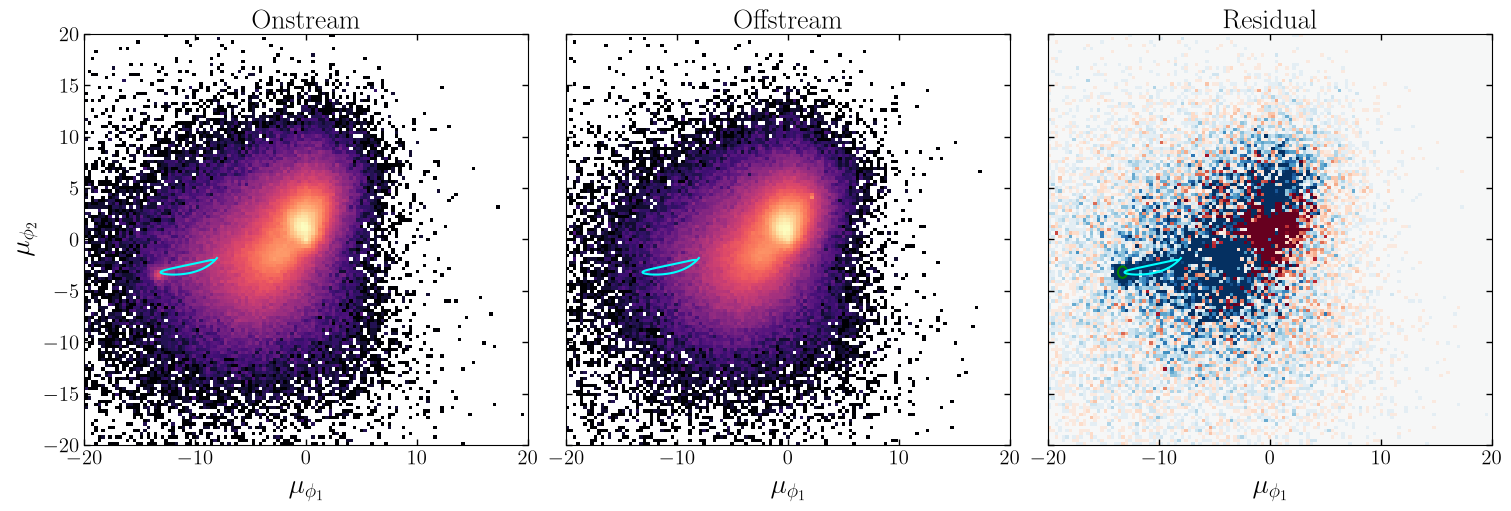

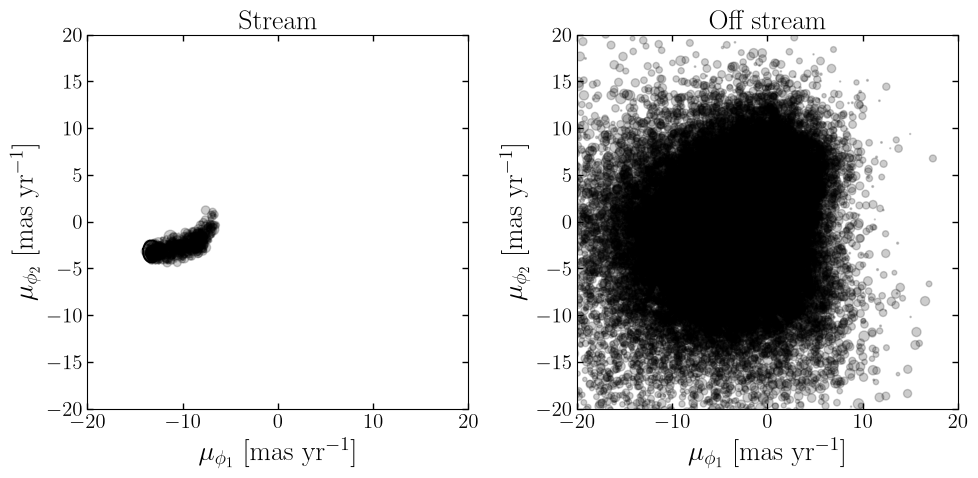

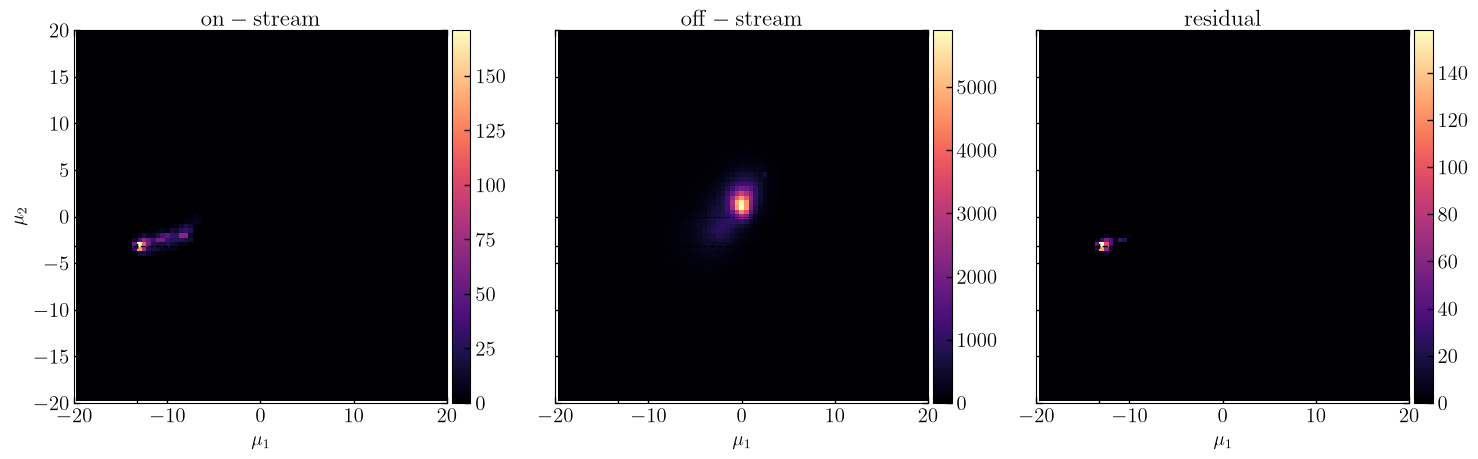

In [37]:
pmsel = ProperMotionSelection(tbl, inputs[stream_name], pprint,
                                n_dispersion_phi1=3, n_dispersion_phi2=3, cutoff=0.1, plot=True)

iso_obj = Isochrone(tbl, inputs[stream_name], pawprint=pmsel.pawprint,)
_, iso_mask, _, hb_mask, pprint = iso_obj.simpleSln(mass_thresh=0.83)

In [38]:
##### rough pm cut to start with (this comes only from the galstreams proper motion tracks)
pawprint.pmprint, pm_mask = rough_pm_poly(pawprint, tbl, buffer=2)

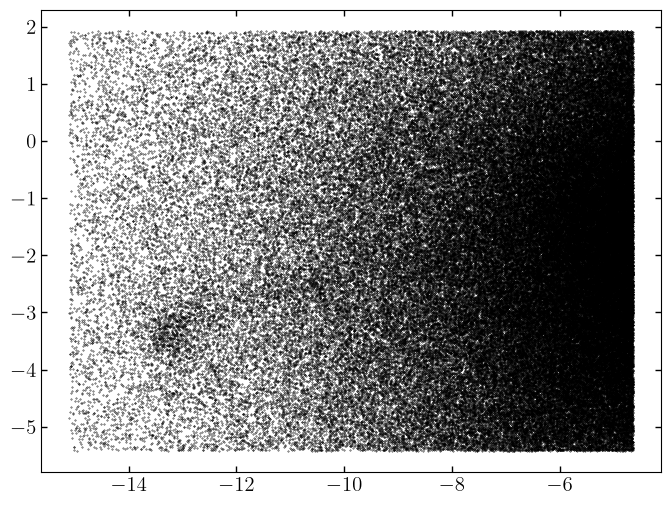

In [39]:
plt.scatter(iso_obj.cat[pm_mask & (iso_mask | hb_mask)]['pm_phi1_cosphi2_unrefl'], iso_obj.cat[pm_mask & (iso_mask | hb_mask)]['pm_phi2_unrefl'], s=0.1)
plt.show()

In [40]:
run_data_ = iso_obj.cat[pm_mask & (iso_mask | hb_mask)]
bkg_data_ = iso_obj.cat[pm_mask & ~iso_obj.on_skymask & (iso_mask | hb_mask)]
stream_data_ = iso_obj.cat[pmsel.pm12_mask & (iso_mask | hb_mask) & iso_obj.on_skymask]

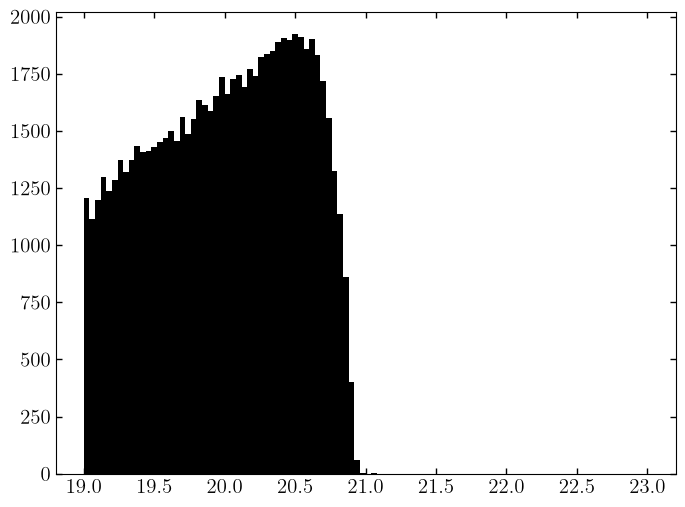

In [42]:
plt.hist(run_data_['phot_g_mean_mag'], bins=100, range=[19,23])
plt.show()

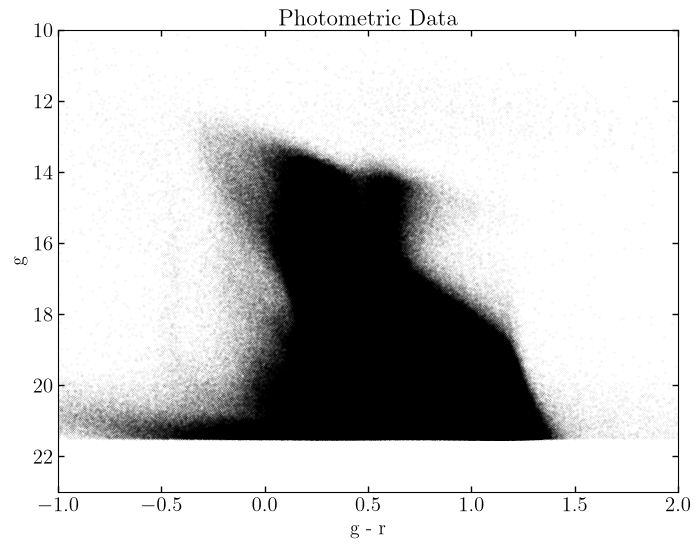

In [43]:
plt.scatter(tbl['g_0'] - tbl['r_0'], tbl['g_0'], s=0.001)
plt.xlabel('g - r')
plt.ylabel('g')
plt.title('Photometric Data')
plt.xlim(-1, 2); plt.ylim(23, 10)
plt.show()

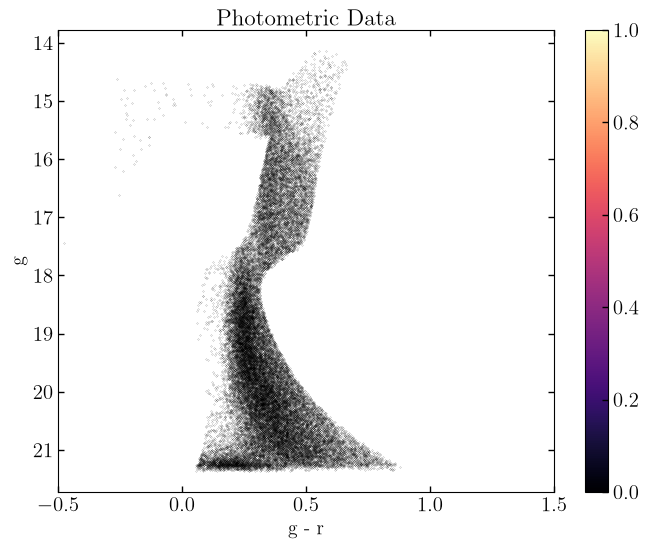

In [44]:
plt.scatter(run_data_['g_0'][np.abs(run_data_['phi1']+40) < 10] - run_data_['r_0'][np.abs(run_data_['phi1']+40) < 10], 
            run_data_['g_0'][np.abs(run_data_['phi1']+40) < 10], s=0.01)
plt.xlabel('g - r')
plt.ylabel('g')
plt.title('Photometric Data')
plt.gca().invert_yaxis()
plt.xlim(-0.5,1.5)
plt.colorbar()

plt.show()

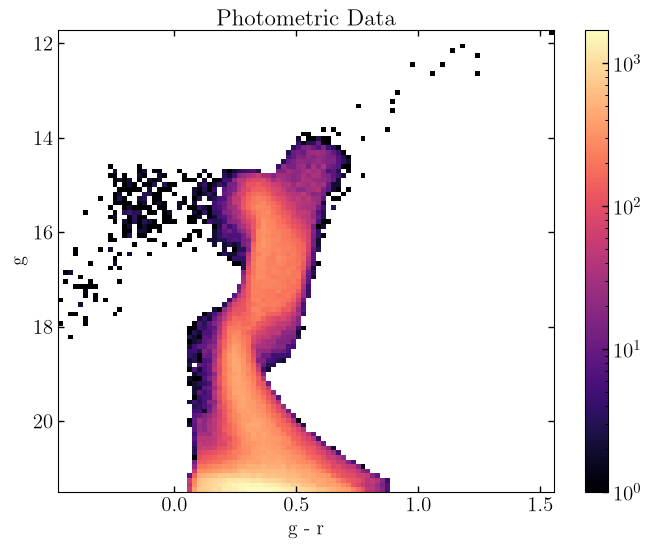

In [45]:
plt.hist2d(run_data_['g_0'] - run_data_['r_0'], run_data_['g_0'], bins=100, norm=mpl.colors.LogNorm())
plt.xlabel('g - r')
plt.ylabel('g')
plt.title('Photometric Data')
plt.gca().invert_yaxis()

plt.colorbar()

plt.show()

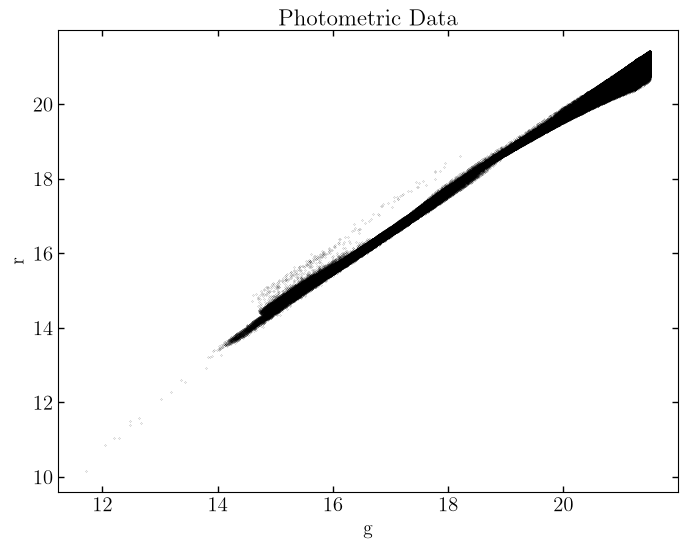

In [46]:
plt.scatter(run_data_['g_0'], run_data_['r_0'], s=0.01)
plt.xlabel('g')
plt.ylabel('r')
plt.title('Photometric Data')
# plt.xlim(-1, 2); plt.ylim(23, 10)
plt.show()

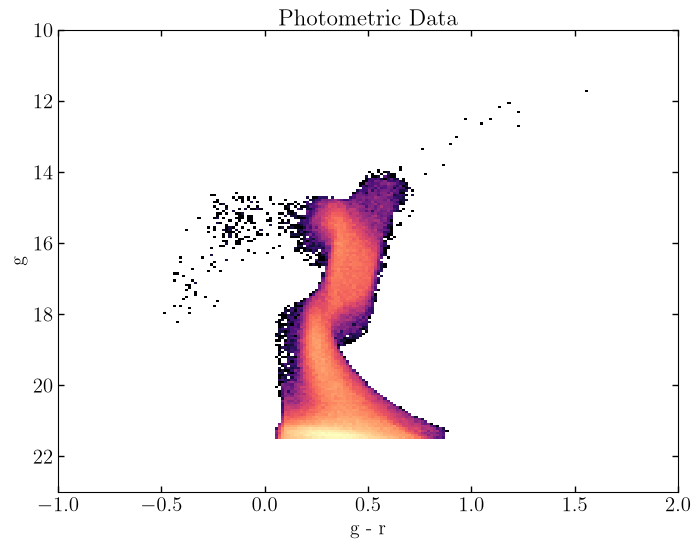

In [47]:
import matplotlib as mpl
plt.hist2d(bkg_data_['g_0'] - bkg_data_['r_0'], bkg_data_['g_0'], bins=200, range=[[-1, 2], [10, 23]], norm=mpl.colors.LogNorm())
plt.xlabel('g - r')
plt.ylabel('g')
plt.title('Photometric Data')
plt.gca().invert_yaxis()
plt.show()

In [48]:
np.sum(run_data_['g_0']<21.5)

np.int64(303346)

In [49]:
import pickle
post_cats = {'run_data': run_data_,
         'bkg_data': bkg_data_,
         'stream_data': stream_data_,
         'pawprint': pawprint,
         'iso_obj': iso_obj}
with open('../../data/for_svi_w_isochrone_cut.pkl', 'wb') as param_file:
    pickle.dump(post_cats, param_file)


In [50]:
len(bkg_data_)

252748

In [51]:
len(stream_data_)

2214

(-8.0, 4.0)

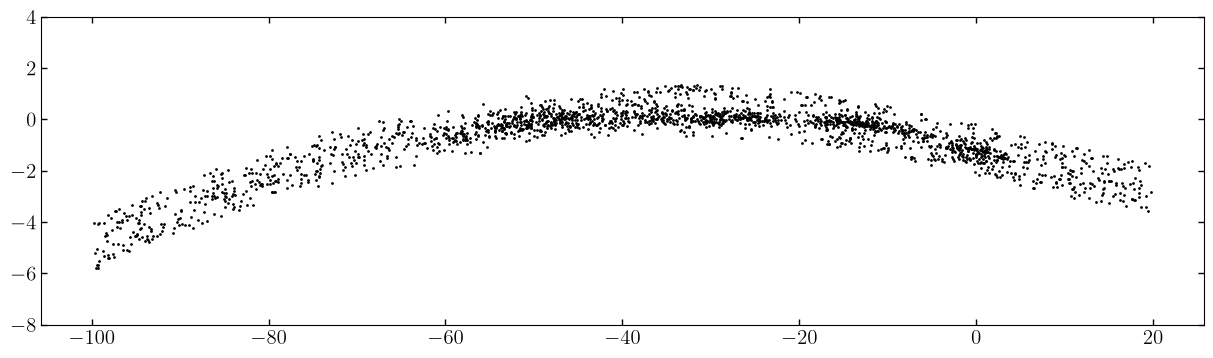

In [52]:
plt.figure(figsize=(15, 4))
plt.scatter(stream_data_['phi1'], stream_data_['phi2'], s=1)
plt.ylim(-8, 4)

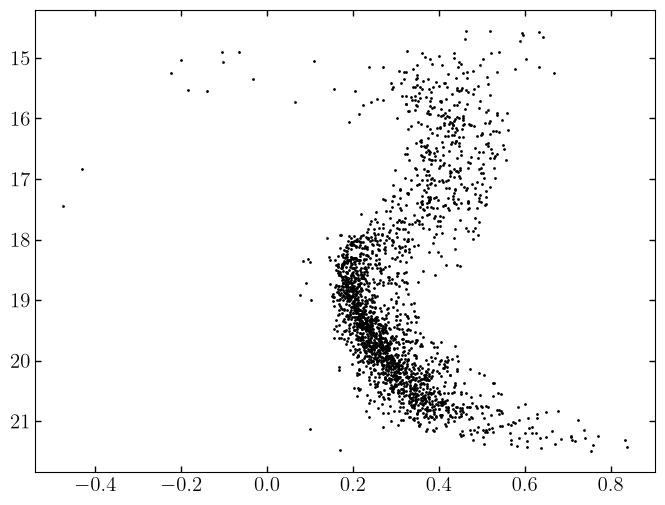

In [53]:
plt.scatter(stream_data_['g_0']-stream_data_['r_0'], stream_data_['g_0'], s=1)
plt.gca().invert_yaxis()
plt.show()

Check Bechtol+15